# Comparing Optimizers on the Same Network

**AIGC 5500 — Week 2, Part 3 — "Try it" exercise**

Takes the corrected network from Part 2 (Xavier init + BatchNorm) and
trains it four times — plain SGD, SGD with momentum, RMSprop, and AdamW —
with the architecture, data, learning rate, and epoch count held
identical across all four runs, then compares the resulting loss curves.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## The network

Exactly Part 2's fixed architecture — Xavier initialization and
BatchNorm before every sigmoid. There is no "broken" branch here; Part 3
starts from the network Part 2 already repaired.

In [2]:
class DeepSigmoidNet(nn.Module):
    """The corrected network from Part 2: Xavier init + BatchNorm before
    every sigmoid.
    """

    def __init__(self, depth, width=32, in_features=32):
        super().__init__()
        linears, norms = [], []
        n_in = in_features
        for _ in range(depth):
            linears.append(nn.Linear(n_in, width))
            norms.append(nn.BatchNorm1d(width))
            n_in = width
        self.linears = nn.ModuleList(linears)
        self.norms = nn.ModuleList(norms)
        self.out = nn.Linear(width, 1)
        for layer in self.linears:
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        for linear, norm in zip(self.linears, self.norms):
            x = torch.sigmoid(norm(linear(x)))
        return self.out(x)

## A toy regression task

A small synthetic dataset with an actual learnable pattern — a noisy
linear combination of the inputs — so the four optimizers have something
real to converge toward and their speeds can be compared honestly.
(Part 1 and Part 2 only needed a single gradient snapshot, so their toy
data could be pure noise; training for many epochs needs a real target.)

In [3]:
def make_toy_regression(n=256, in_features=32, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, in_features, generator=g)
    true_w = torch.randn(in_features, 1, generator=g)
    noise = 0.1 * torch.randn(n, 1, generator=g)
    y = x @ true_w * 0.3 + noise
    return x, y

## The training loop, parameterized by optimizer

The same five-step loop from Week 1, with only the optimizer swapped
out. Everything else — model, data, seed, learning rate, epoch count —
stays fixed across the four runs.

In [4]:
def train(depth, optimizer_name, lr, epochs, seed=0):
    torch.manual_seed(seed)
    model = DeepSigmoidNet(depth=depth)
    x, y = make_toy_regression(seed=0)

    if optimizer_name == "SGD":
        opt = torch.optim.SGD(model.parameters(), lr=lr)
    elif optimizer_name == "SGD+momentum":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif optimizer_name == "RMSprop":
        opt = torch.optim.RMSprop(model.parameters(), lr=lr)
    elif optimizer_name == "AdamW":
        opt = torch.optim.AdamW(model.parameters(), lr=lr)
    else:
        raise ValueError(optimizer_name)

    history = []
    for epoch in range(epochs):
        opt.zero_grad()              # 1. clear old gradients
        preds = model(x)             # 2. forward pass
        loss = nn.functional.mse_loss(preds, y)  # 3. compute the loss
        loss.backward()              # 4. backward pass
        opt.step()                   # 5. update parameters
        history.append(loss.item())
    return history

## Run all four optimizers

Same depth (20 — Part 2's headline case), same learning rate, same
number of epochs.

In [5]:
depth, lr, epochs = 20, 0.01, 150
optimizers = ["SGD", "SGD+momentum", "RMSprop", "AdamW"]

histories = {name: train(depth, name, lr, epochs) for name in optimizers}

print(f"{'Optimizer':>14} | {'epoch 0':>10} | {'epoch 50':>10} | {'epoch 149':>10}")
print("-" * 54)
for name, h in histories.items():
    nan_flag = " (NaN!)" if any(v != v for v in h) else ""
    print(f"{name:>14} | {h[0]:>10.4f} | {h[50]:>10.4f} | {h[-1]:>10.4f}{nan_flag}")

     Optimizer |    epoch 0 |   epoch 50 |  epoch 149
------------------------------------------------------
           SGD |     2.6209 |     0.8057 |     0.1171
  SGD+momentum |     2.6209 |     0.0522 |     0.0008
       RMSprop |     2.6209 |     0.4928 |     0.0690
         AdamW |     2.6209 |     0.0689 |     0.0070


By epoch 50, SGD with momentum and AdamW are both well ahead of plain
SGD, with RMSprop in between — the ranking Part 3 predicts. But run the
plot below before deciding this is simply a story about speed.

## Plot all four loss curves together

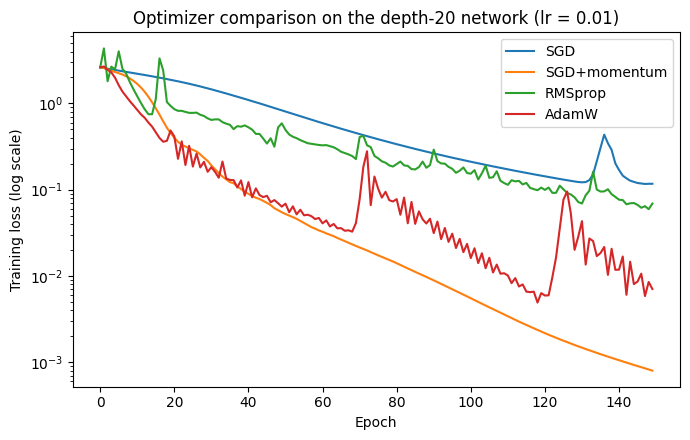

In [6]:
plt.figure(figsize=(7, 4.5))
for name, h in histories.items():
    plt.plot(h, label=name)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training loss (log scale)")
plt.title(f"Optimizer comparison on the depth-{depth} network (lr = {lr})")
plt.legend()
plt.tight_layout()
plt.savefig("optimizer_comparison.png", dpi=150)
plt.show()

## Takeaway

Look closely at the curves rather than just their endpoints. SGD with
momentum is both the fastest and the smoothest of the four — its
loss decreases almost monotonically. RMSprop and AdamW converge faster
than plain SGD on average, but neither is smooth: both show repeated
sharp spikes where the loss jumps up by an order of magnitude before
resuming its decrease. Plain SGD shows one such spike too, later and
smaller. This is the instability the Try it exercise asks you to watch
for — it was there all along, just not visible from the final-epoch
number alone.

The spikes are not a bug in this notebook; they are a real, documented
behaviour of adaptive optimizers. RMSprop and AdamW both divide each
parameter's update by a running estimate of that parameter's recent
squared gradient. During a calm stretch, that running estimate shrinks
— which *increases* the effective step size for the next update. If a
larger-than-usual gradient then arrives while the denominator is small,
the resulting step overshoots, producing the spike, before the
optimizer's running statistics catch up and it resumes descending.
Momentum, by contrast, smooths the update directly rather than rescaling
it adaptively, which is why SGD+momentum here is both fast and free of
this failure mode.

Try lowering `lr` in the run cell above — the spikes in RMSprop and
AdamW should shrink or disappear, at the cost of slower convergence
overall. That trade-off, not a simple "Adam is always better" story, is
the actual lesson this exercise is checking for.